In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy import signal

print("Ambiente SDR configurado com sucesso!")


Ambiente SDR configurado com sucesso!


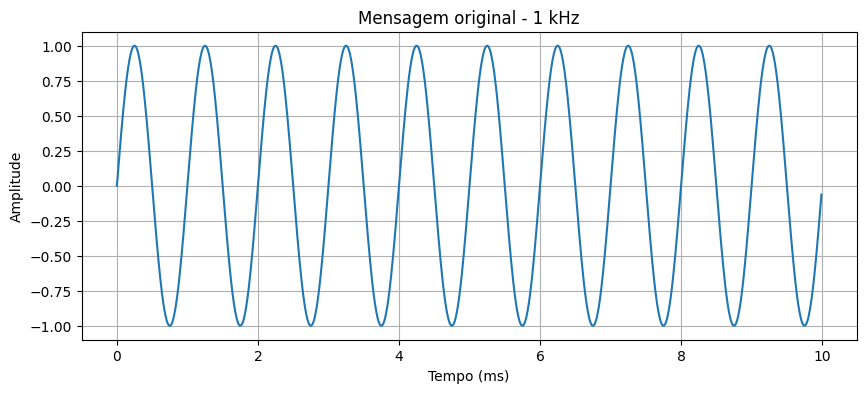

In [2]:

# Parâmetros do sinal
fs = 100000       # Frequência de amostragem: 100 kHz
fm = 1000         # Frequência da mensagem: 1 kHz
duracao = 0.01    # Duração: 10 ms

# Vetor de tempo
t = np.arange(0, duracao, 1/fs)

# Sinal de mensagem
mensagem = np.sin(2*np.pi*fm*t)

# Visualização
plt.figure(figsize=(10,4))
plt.plot(t*1000, mensagem)

plt.title("Mensagem original - 1 kHz")
plt.xlabel("Tempo (ms)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


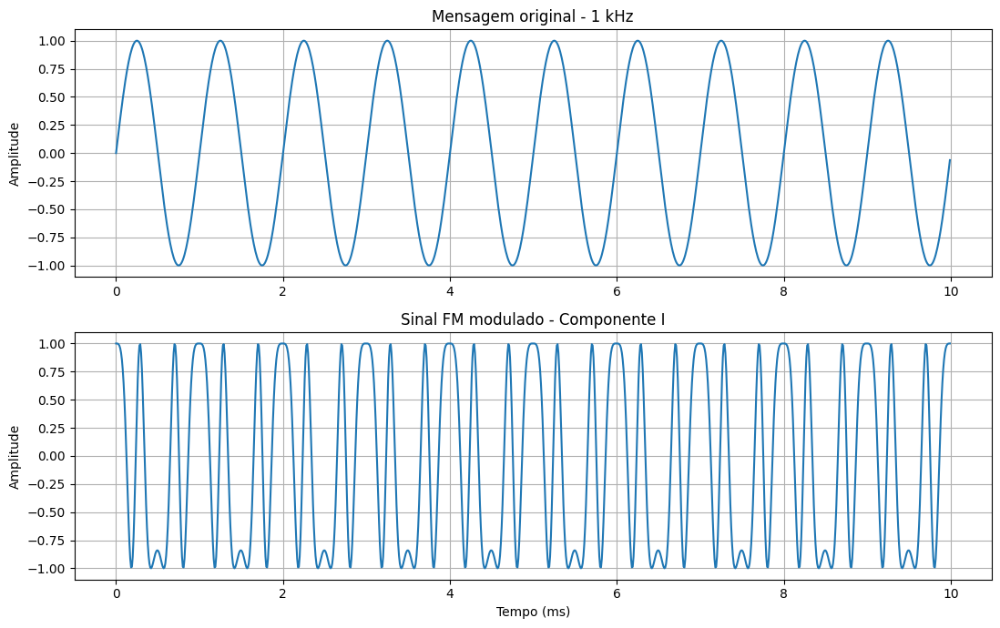

In [3]:

# ETAPA 5 - MODULAÇÃO FM

# Desvio máximo de frequência
desvio = 5000  # 5 kHz

# Frequência instantânea em banda-base
f_inst = desvio * mensagem

# Fase instantânea
fase = 2 * np.pi * np.cumsum(f_inst) / fs

# Sinal FM complexo (IQ)
sinal_fm = np.exp(1j * fase)

# Visualização
fig, ax = plt.subplots(2, 1, figsize=(11, 7))

# Mensagem original
ax[0].plot(t*1000, mensagem)
ax[0].set_title("Mensagem original - 1 kHz")
ax[0].set_ylabel("Amplitude")
ax[0].grid(True)

# Parte real do sinal FM
ax[1].plot(t*1000, np.real(sinal_fm))
ax[1].set_title("Sinal FM modulado - Componente I")
ax[1].set_xlabel("Tempo (ms)")
ax[1].set_ylabel("Amplitude")
ax[1].grid(True)

plt.tight_layout()
plt.show()


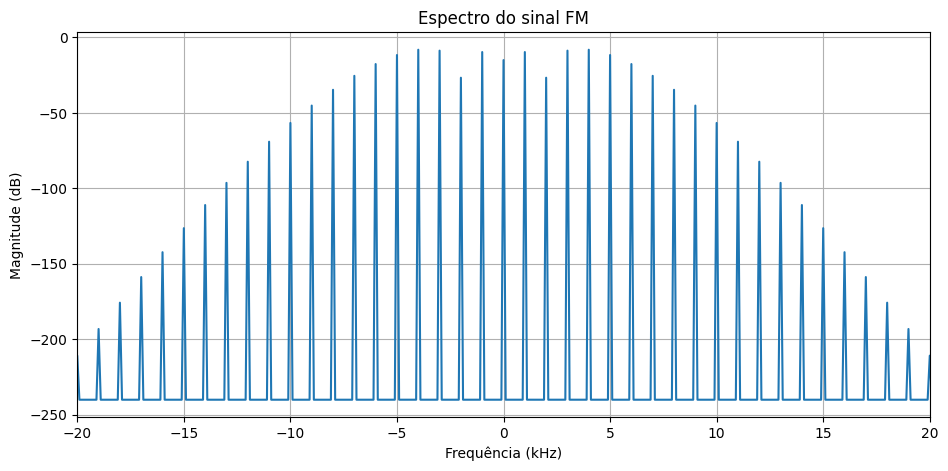

In [4]:

# ETAPA 6 - ANÁLISE ESPECTRAL DO SINAL FM

N = len(sinal_fm)

# Aplicando a FFT
espectro = np.fft.fft(sinal_fm)

# Centralizando a frequência zero
espectro = np.fft.fftshift(espectro)

# Eixo de frequências
freq = np.fft.fftshift(np.fft.fftfreq(N, d=1/fs))

# Normalização e conversão para dB
magnitude = 20*np.log10(np.abs(espectro)/N + 1e-12)

# Gráfico
plt.figure(figsize=(11,5))
plt.plot(freq/1000, magnitude)

plt.title("Espectro do sinal FM")
plt.xlabel("Frequência (kHz)")
plt.ylabel("Magnitude (dB)")
plt.xlim(-20,20)
plt.grid(True)

plt.show()


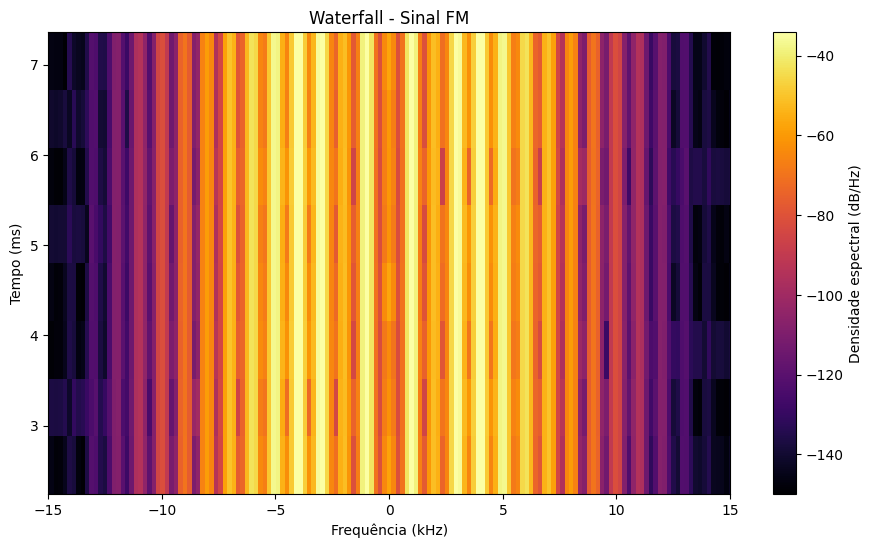

In [5]:

# ETAPA 7 - WATERFALL DO SINAL FM

from scipy.signal import spectrogram

# Calculando o espectrograma
freq_w, tempo_w, Sxx = spectrogram(
    sinal_fm,
    fs=fs,
    window="hann",
    nperseg=512,
    noverlap=448,
    return_onesided=False,
    mode="psd"
)

# Centralizando as frequências
freq_w = np.fft.fftshift(freq_w)
Sxx = np.fft.fftshift(Sxx, axes=0)

# Convertendo para dB
Sxx_dB = 10*np.log10(Sxx + 1e-15)

# Waterfall
plt.figure(figsize=(11,6))

plt.pcolormesh(
    freq_w/1000,
    tempo_w*1000,
    Sxx_dB.T,
    shading="auto",
    cmap="inferno"
)

plt.colorbar(label="Densidade espectral (dB/Hz)")

plt.title("Waterfall - Sinal FM")
plt.xlabel("Frequência (kHz)")
plt.ylabel("Tempo (ms)")
plt.xlim(-15,15)

plt.show()


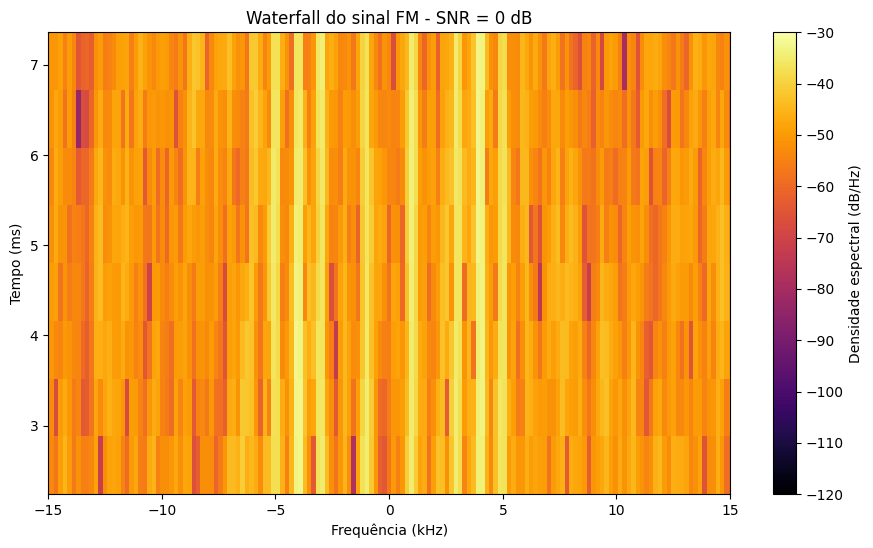

In [18]:

# ETAPA 8 - CANAL AWGN

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import spectrogram

# Relação sinal-ruído desejada
SNR_dB = 0

# Potência média do sinal FM
potencia_sinal = np.mean(np.abs(sinal_fm)**2)

# Potência do ruído
potencia_ruido = potencia_sinal / (10**(SNR_dB/10))

# Gerando ruído complexo AWGN
rng = np.random.default_rng(42)

ruido = np.sqrt(potencia_ruido/2) * (
    rng.standard_normal(len(sinal_fm)) +
    1j*rng.standard_normal(len(sinal_fm))
)

# Sinal recebido
sinal_recebido = sinal_fm + ruido

# Espectrograma do sinal recebido
f, tempo, Sxx = spectrogram(
    sinal_recebido,
    fs=fs,
    window="hann",
    nperseg=512,
    noverlap=448,
    return_onesided=False,
    mode="psd"
)

f = np.fft.fftshift(f)
Sxx = np.fft.fftshift(Sxx, axes=0)

Sxx_dB = 10*np.log10(Sxx + 1e-15)

plt.figure(figsize=(11,6))

plt.pcolormesh(
    f/1000,
    tempo*1000,
    Sxx_dB.T,
    shading="auto",
    cmap="inferno",
    vmin=-120,
    vmax=-30
)
plt.colorbar(label="Densidade espectral (dB/Hz)")
plt.title(f"Waterfall do sinal FM - SNR = {SNR_dB} dB")
plt.xlabel("Frequência (kHz)")
plt.ylabel("Tempo (ms)")
plt.xlim(-15,15)

plt.show()


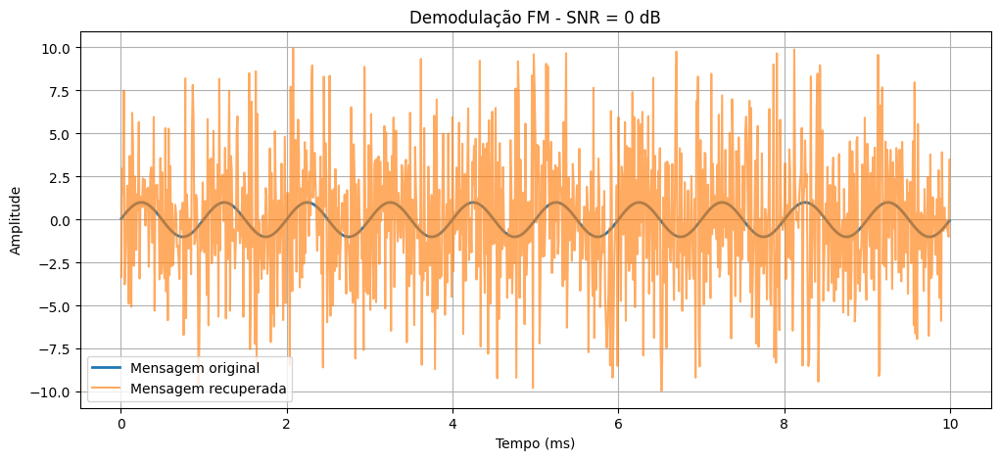

In [19]:

# ETAPA 10 - DEMODULADOR FM

# Demodulação por diferença de fase
fase_diferencial = np.angle(
    sinal_recebido[1:] *
    np.conj(sinal_recebido[:-1])
)

# Recuperação da mensagem
mensagem_recuperada = (
    fase_diferencial * fs / (2*np.pi*desvio)
)

# Comparação com a mensagem original
plt.figure(figsize=(12,5))

plt.plot(
    t[1:]*1000,
    mensagem[1:],
    label="Mensagem original",
    linewidth=2
)

plt.plot(
    t[1:]*1000,
    mensagem_recuperada,
    label="Mensagem recuperada",
    alpha=0.65
)

plt.title(f"Demodulação FM - SNR = {SNR_dB} dB")
plt.xlabel("Tempo (ms)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()


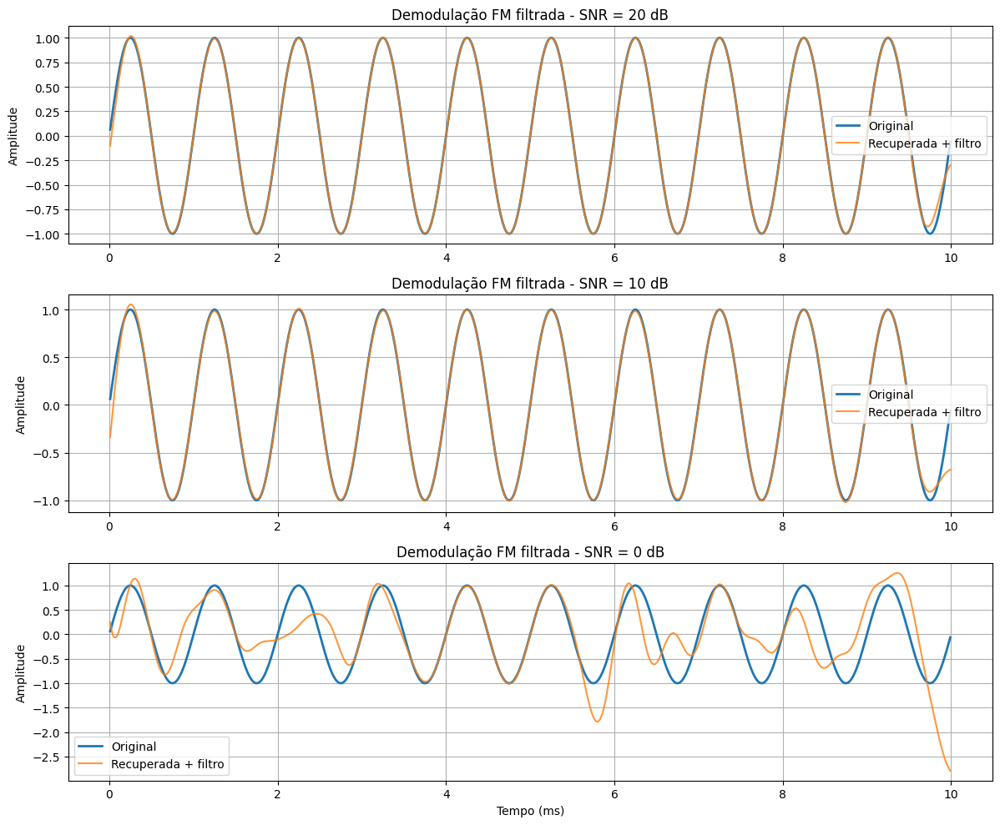

In [20]:

# ETAPA 11 - FILTRAGEM DIGITAL

from scipy.signal import butter, sosfiltfilt

# Filtro Butterworth de 4ª ordem
fc = 2000  # Frequência de corte: 2 kHz

sos = butter(
    4,
    fc,
    btype="low",
    fs=fs,
    output="sos"
)

# Comparação para diferentes SNRs
fig, axes = plt.subplots(3, 1, figsize=(12, 10))

rng = np.random.default_rng(42)

for ax, snr_db in zip(axes, [20, 10, 0]):

    potencia_sinal = np.mean(np.abs(sinal_fm)**2)
    potencia_ruido = potencia_sinal / 10**(snr_db/10)

    ruido = np.sqrt(potencia_ruido/2) * (
        rng.standard_normal(len(sinal_fm)) +
        1j*rng.standard_normal(len(sinal_fm))
    )

    recebido = sinal_fm + ruido

    # Demodulação FM
    fase_diff = np.angle(
        recebido[1:] * np.conj(recebido[:-1])
    )

    demodulado = fase_diff * fs / (2*np.pi*desvio)

    # Filtragem passa-baixa
    filtrado = sosfiltfilt(sos, demodulado)

    # Gráficos
    ax.plot(
        t[1:]*1000, mensagem[1:],
        label="Original", linewidth=2
    )

    ax.plot(
        t[1:]*1000, filtrado,
        label="Recuperada + filtro",
        alpha=0.8
    )

    ax.set_title(f"Demodulação FM filtrada - SNR = {snr_db} dB")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True)

axes[-1].set_xlabel("Tempo (ms)")
plt.tight_layout()
plt.show()


In [21]:

# ETAPA 12 - AVALIAÇÃO QUANTITATIVA

resultados = []

rng = np.random.default_rng(42)

for snr_db in [20, 10, 0]:

    potencia_sinal = np.mean(np.abs(sinal_fm)**2)
    potencia_ruido = potencia_sinal / (10**(snr_db/10))

    ruido = np.sqrt(potencia_ruido/2) * (
        rng.standard_normal(len(sinal_fm)) +
        1j*rng.standard_normal(len(sinal_fm))
    )

    recebido = sinal_fm + ruido

    # Demodulação FM
    fase_diff = np.angle(
        recebido[1:] * np.conj(recebido[:-1])
    )

    demodulado = fase_diff * fs / (2*np.pi*desvio)

    # Filtragem
    filtrado = sosfiltfilt(sos, demodulado)

    # Remover bordas para evitar efeitos transitórios
    margem = 100

    original = mensagem[1:][margem:-margem]
    estimado = filtrado[margem:-margem]

    # Erro
    erro = original - estimado

    mse = np.mean(erro**2)

    snr_saida = 10*np.log10(
        np.mean(original**2) / np.mean(erro**2)
    )

    resultados.append((snr_db, mse, snr_saida))

# Mostrar resultados
print("SNR Entrada | MSE | SNR Saída")
print("-"*42)

for snr, mse, snr_out in resultados:
    print(f"{snr:>6} dB    | {mse:.5f} | {snr_out:.2f} dB")


SNR Entrada | MSE | SNR Saída
------------------------------------------
    20 dB    | 0.00001 | 45.74 dB
    10 dB    | 0.00011 | 36.64 dB
     0 dB    | 0.19554 | 4.08 dB


In [22]:

# ETAPA 13 - INTERFACE SDR INTERATIVA

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from IPython.display import display
from scipy.signal import spectrogram

def painel_sdr(snr_db=20, fm_hz=1000):

    fs_local = 100000
    duracao_local = 0.1
    desvio_local = 5000

    t_local = np.arange(
        int(fs_local * duracao_local)
    ) / fs_local

    # Mensagem
    msg = np.sin(2*np.pi*fm_hz*t_local)

    # Modulação FM
    fase = 2*np.pi*desvio_local*np.cumsum(msg)/fs_local
    iq = np.exp(1j*fase)

    # Canal AWGN
    rng = np.random.default_rng(42)

    p_sinal = np.mean(np.abs(iq)**2)
    p_ruido = p_sinal / (10**(snr_db/10))

    ruido = np.sqrt(p_ruido/2) * (
        rng.standard_normal(len(iq)) +
        1j*rng.standard_normal(len(iq))
    )

    rx = iq + ruido

    # FFT
    N = len(rx)
    freq = np.fft.fftshift(
        np.fft.fftfreq(N, 1/fs_local)
    )

    fft = np.fft.fftshift(np.fft.fft(rx))
    mag = 20*np.log10(np.abs(fft)/N + 1e-12)

    # Waterfall
    fw, tw, Sxx = spectrogram(
        rx,
        fs=fs_local,
        nperseg=512,
        noverlap=448,
        return_onesided=False
    )

    fw = np.fft.fftshift(fw)
    Sxx = np.fft.fftshift(Sxx, axes=0)

    # Painel
    fig, ax = plt.subplots(3, 1, figsize=(12, 10))

    ax[0].plot(t_local*1000, msg)
    ax[0].set_xlim(0, 10)
    ax[0].set_title("Mensagem original")
    ax[0].set_xlabel("Tempo (ms)")
    ax[0].grid(True)

    ax[1].plot(freq/1000, mag)
    ax[1].set_xlim(-15, 15)
    ax[1].set_title("Espectro FFT")
    ax[1].set_xlabel("Frequência (kHz)")
    ax[1].set_ylabel("Magnitude (dB)")
    ax[1].grid(True)

    im = ax[2].pcolormesh(
        fw/1000,
        tw*1000,
        10*np.log10(Sxx.T + 1e-15),
        shading="auto",
        cmap="inferno",
        vmin=-120,
        vmax=-30
    )

    ax[2].set_xlim(-15, 15)
    ax[2].set_title("Waterfall")
    ax[2].set_xlabel("Frequência (kHz)")
    ax[2].set_ylabel("Tempo (ms)")

    fig.colorbar(im, ax=ax[2], label="PSD (dB/Hz)")
    plt.tight_layout()
    plt.show()

# Controles interativos
widgets.interact(
    painel_sdr,
    snr_db=widgets.IntSlider(
        value=20, min=0, max=30, step=5,
        description="SNR (dB)"
    ),
    fm_hz=widgets.IntSlider(
        value=1000, min=500, max=5000, step=500,
        description="Freq. (Hz)"
    )
)


interactive(children=(IntSlider(value=20, description='SNR (dB)', max=30, step=5), IntSlider(value=1000, descr…

<function __main__.painel_sdr(snr_db=20, fm_hz=1000)>

In [23]:

# ETAPA 14 - RECEPTOR FM INTERATIVO

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from scipy.signal import butter, sosfiltfilt

def receptor_fm(snr_db=20, fm_hz=1000):

    fs = 100000
    duracao = 0.1
    desvio = 5000

    t = np.arange(int(fs*duracao))/fs

    # 1. Mensagem original
    mensagem = np.sin(2*np.pi*fm_hz*t)

    # 2. Modulação FM
    fase = 2*np.pi*desvio*np.cumsum(mensagem)/fs
    iq = np.exp(1j*fase)

    # 3. Canal com ruído
    rng = np.random.default_rng(42)

    potencia_ruido = np.mean(np.abs(iq)**2) / (
        10**(snr_db/10)
    )

    ruido = np.sqrt(potencia_ruido/2) * (
        rng.standard_normal(len(iq)) +
        1j*rng.standard_normal(len(iq))
    )

    recebido = iq + ruido

    # 4. Demodulação FM
    fase_diff = np.angle(
        recebido[1:] * np.conj(recebido[:-1])
    )

    demodulado = fase_diff*fs/(2*np.pi*desvio)

    # 5. Filtro passa-baixa
    fc = min(1.5*fm_hz, 0.45*fs)

    sos = butter(
        4, fc, btype="low",
        fs=fs, output="sos"
    )

    recuperado = sosfiltfilt(sos, demodulado)

    # 6. Cálculo do erro (sem as bordas)
    margem = 100

    original = mensagem[1:][margem:-margem]
    estimado = recuperado[margem:-margem]

    mse = np.mean((original-estimado)**2)

    snr_saida = 10*np.log10(
        np.mean(original**2) / mse
    )

    # 7. Gráfico
    plt.figure(figsize=(12,5))

    plt.plot(
        t[1:]*1000, mensagem[1:],
        label="Mensagem original",
        linewidth=2
    )

    plt.plot(
        t[1:]*1000, recuperado,
        label="Mensagem recuperada",
        alpha=0.8
    )

    plt.xlim(0, 10)
    plt.xlabel("Tempo (ms)")
    plt.ylabel("Amplitude")

    plt.title(
        f"Receptor FM | SNR entrada = {snr_db} dB"
    )

    plt.legend()
    plt.grid(True)
    plt.show()

    print(f"MSE: {mse:.6f}")
    print(f"SNR de saída: {snr_saida:.2f} dB")


widgets.interact(
    receptor_fm,
    snr_db=widgets.IntSlider(
        value=20, min=0, max=30,
        step=5, description="SNR (dB)"
    ),
    fm_hz=widgets.IntSlider(
        value=1000, min=500, max=5000,
        step=500, description="Freq. (Hz)"
    )
)


interactive(children=(IntSlider(value=20, description='SNR (dB)', max=30, step=5), IntSlider(value=1000, descr…

<function __main__.receptor_fm(snr_db=20, fm_hz=1000)>

In [24]:

# ETAPA 15 - PAINEL SDR COMPLETO

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from scipy.signal import butter, sosfiltfilt, spectrogram
from IPython.display import display

def sdr_lab(snr_db=20, fm_hz=1000):

    fs = 100_000
    duracao = 0.1
    desvio = 5000

    t = np.arange(int(fs*duracao))/fs

    # Mensagem original
    mensagem = np.sin(2*np.pi*fm_hz*t)

    # Modulação FM em banda-base IQ
    fase = 2*np.pi*desvio*np.cumsum(mensagem)/fs
    iq = np.exp(1j*fase)

    # Canal AWGN
    rng = np.random.default_rng(42)
    p_ruido = np.mean(np.abs(iq)**2) / 10**(snr_db/10)

    ruido = np.sqrt(p_ruido/2) * (
        rng.standard_normal(len(iq)) +
        1j*rng.standard_normal(len(iq))
    )

    rx = iq + ruido

    # Demodulação
    fase_diff = np.angle(rx[1:] * np.conj(rx[:-1]))
    demodulado = fase_diff*fs/(2*np.pi*desvio)

    # Filtro passa-baixa
    fc = 1.5*fm_hz
    sos = butter(4, fc, fs=fs, btype="low", output="sos")
    recuperado = sosfiltfilt(sos, demodulado)

    # Métricas, excluindo as bordas
    margem = 100
    original = mensagem[1:][margem:-margem]
    estimado = recuperado[margem:-margem]

    mse = np.mean((original-estimado)**2)
    snr_saida = 10*np.log10(
        np.mean(original**2) / max(mse, 1e-15)
    )

    # FFT com janela Hann
    N = len(rx)
    janela = np.hanning(N)
    fft = np.fft.fftshift(np.fft.fft(rx*janela))
    freq = np.fft.fftshift(np.fft.fftfreq(N, 1/fs))
    mag = 20*np.log10(
        np.abs(fft)/np.sum(janela) + 1e-12
    )

    # Waterfall
    fw, tw, Sxx = spectrogram(
        rx, fs=fs, window="hann",
        nperseg=512, noverlap=448,
        return_onesided=False
    )

    fw = np.fft.fftshift(fw)
    Sxx = np.fft.fftshift(Sxx, axes=0)

    # Interface
    fig, ax = plt.subplots(3, 1, figsize=(12, 11))

    ax[0].plot(freq/1000, mag)
    ax[0].set_xlim(-15, 15)
    ax[0].set_title("Espectro FFT")
    ax[0].set_xlabel("Frequência (kHz)")
    ax[0].set_ylabel("Magnitude (dB)")
    ax[0].grid(True)

    im = ax[1].pcolormesh(
        fw/1000, tw*1000,
        10*np.log10(Sxx.T + 1e-15),
        shading="auto", cmap="inferno",
        vmin=-120, vmax=-30
    )

    ax[1].set_xlim(-15, 15)
    ax[1].set_title("Waterfall")
    ax[1].set_xlabel("Frequência (kHz)")
    ax[1].set_ylabel("Tempo (ms)")
    fig.colorbar(im, ax=ax[1], label="PSD (dB/Hz)")

    ax[2].plot(
        t[1:]*1000, mensagem[1:],
        label="Original", linewidth=2
    )
    ax[2].plot(
        t[1:]*1000, recuperado,
        label="Recuperada", alpha=0.8
    )
    ax[2].set_xlim(0, 10)
    ax[2].set_title("Demodulação FM")
    ax[2].set_xlabel("Tempo (ms)")
    ax[2].set_ylabel("Amplitude")
    ax[2].legend()
    ax[2].grid(True)

    plt.tight_layout()
    plt.show()

    print("=== DESEMPENHO DO RECEPTOR ===")
    print(f"SNR de entrada: {snr_db} dB")
    print(f"Frequência da mensagem: {fm_hz} Hz")
    print(f"MSE: {mse:.6f}")
    print(f"SNR de saída: {snr_saida:.2f} dB")


widgets.interact(
    sdr_lab,
    snr_db=widgets.IntSlider(
        value=20, min=0, max=30,
        step=5, description="SNR (dB)"
    ),
    fm_hz=widgets.IntSlider(
        value=1000, min=500, max=5000,
        step=500, description="Freq. (Hz)"
    )
)


interactive(children=(IntSlider(value=20, description='SNR (dB)', max=30, step=5), IntSlider(value=1000, descr…

<function __main__.sdr_lab(snr_db=20, fm_hz=1000)>

Áudio original:


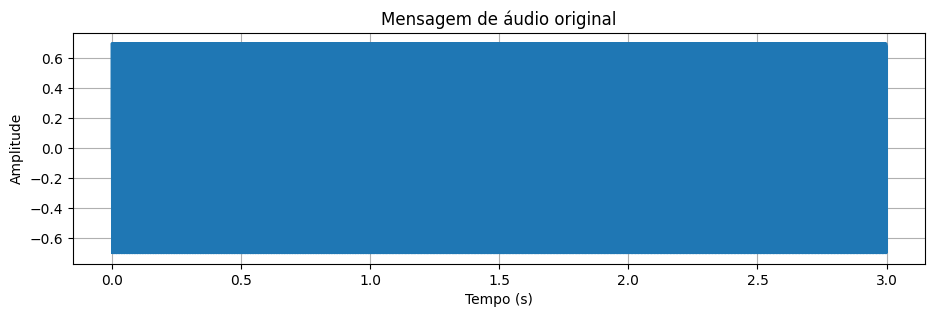

In [25]:

# ETAPA 16 - GERANDO UMA MENSAGEM DE ÁUDIO

import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

fs_audio = 16000
duracao_audio = 3

t_audio = np.arange(
    int(fs_audio * duracao_audio)
) / fs_audio

# Três notas musicais
frequencias = [440, 523.25, 659.25]

audio_original = np.zeros_like(t_audio)

for i, f in enumerate(frequencias):
    inicio = i * fs_audio
    fim = (i + 1) * fs_audio

    tempo_nota = np.arange(fs_audio) / fs_audio

    audio_original[inicio:fim] = (
        0.7 * np.sin(2*np.pi*f*tempo_nota)
    )

# Reproduzir o áudio
print("Áudio original:")
display(Audio(audio_original, rate=fs_audio))

# Visualizar o sinal
plt.figure(figsize=(11, 3))
plt.plot(t_audio, audio_original)
plt.title("Mensagem de áudio original")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()


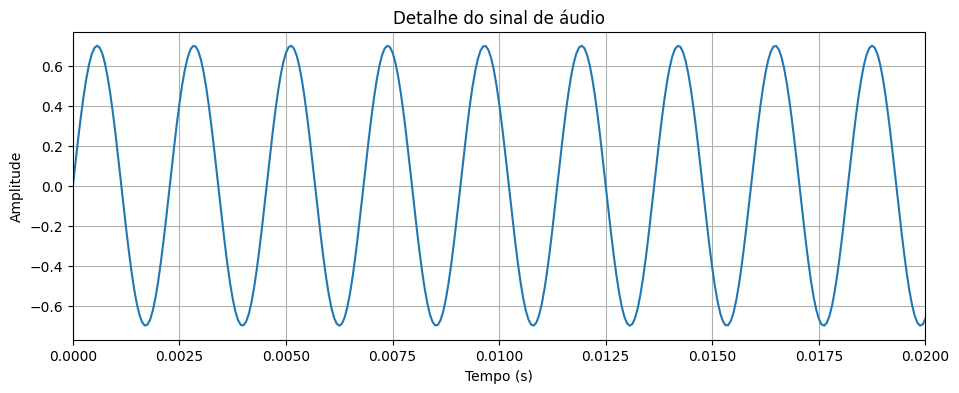

In [26]:
plt.figure(figsize=(11, 4))
plt.plot(t_audio, audio_original)
plt.xlim(0, 0.02)  # Apenas os primeiros 20 ms
plt.title("Detalhe do sinal de áudio")
plt.xlabel("Tempo (s)")
plt.ylabel("Amplitude")
plt.grid(True)
plt.show()

In [27]:

# ETAPA 17 - TRANSMISSÃO E RECEPÇÃO FM DE ÁUDIO

import numpy as np
from scipy.signal import butter, sosfiltfilt
from IPython.display import Audio, display

fs = fs_audio
desvio = 3000       # Desvio máximo: 3 kHz
SNR_dB = 20

# 1. Modulação FM em banda-base
fase = 2*np.pi*desvio*np.cumsum(audio_original)/fs
sinal_fm_audio = np.exp(1j*fase)

# 2. Adicionar ruído AWGN
rng = np.random.default_rng(42)

potencia_sinal = np.mean(np.abs(sinal_fm_audio)**2)
potencia_ruido = potencia_sinal / (10**(SNR_dB/10))

ruido = np.sqrt(potencia_ruido/2) * (
    rng.standard_normal(len(sinal_fm_audio)) +
    1j*rng.standard_normal(len(sinal_fm_audio))
)

recebido = sinal_fm_audio + ruido

# 3. Demodulação FM
fase_diff = np.angle(
    recebido[1:] * np.conj(recebido[:-1])
)

audio_demodulado = fase_diff * fs / (2*np.pi*desvio)

# 4. Filtragem passa-baixa
sos = butter(
    4, 2000,
    btype="low",
    fs=fs,
    output="sos"
)

audio_recuperado = sosfiltfilt(
    sos, audio_demodulado
)

# 5. Comparar os áudios
print("Áudio original:")
display(Audio(audio_original, rate=fs, normalize=False))

print("Áudio recuperado pelo receptor FM:")
display(Audio(audio_recuperado, rate=fs, normalize=False))


Áudio original:


Áudio recuperado pelo receptor FM:



Áudio recuperado - SNR = 20 dB



Áudio recuperado - SNR = 10 dB



Áudio recuperado - SNR = 0 dB


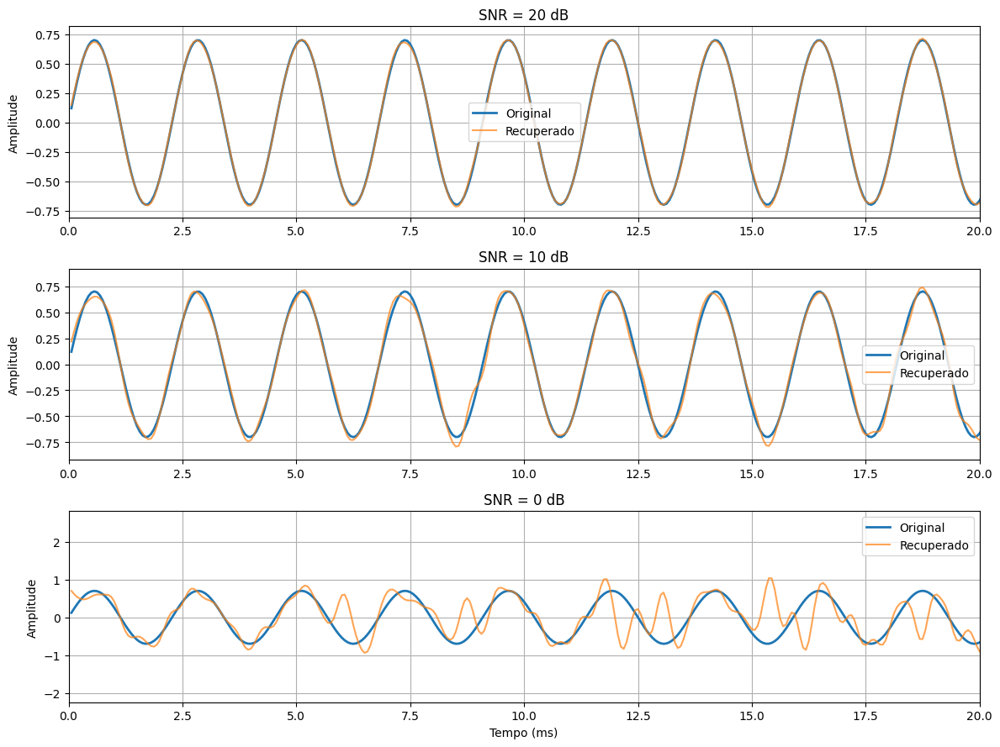

In [29]:

# ETAPA 18 - COMPARAÇÃO DE ÁUDIO PARA DIFERENTES SNRs

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from IPython.display import Audio, display

fs = fs_audio
desvio = 3000

# Filtro de áudio
sos = butter(
    4, 2000,
    btype="low",
    fs=fs,
    output="sos"
)

resultados_audio = {}

for snr_db in [20, 10, 0]:

    rng = np.random.default_rng(42)

    potencia_ruido = (
        np.mean(np.abs(sinal_fm_audio)**2)
        / 10**(snr_db/10)
    )

    ruido = np.sqrt(potencia_ruido/2) * (
        rng.standard_normal(len(sinal_fm_audio)) +
        1j*rng.standard_normal(len(sinal_fm_audio))
    )

    recebido = sinal_fm_audio + ruido

    # Demodulação FM
    fase_diff = np.angle(
        recebido[1:] * np.conj(recebido[:-1])
    )

    demodulado = fase_diff * fs / (2*np.pi*desvio)

    # Filtragem
    recuperado = sosfiltfilt(sos, demodulado)

    resultados_audio[snr_db] = recuperado

    print(f"\nÁudio recuperado - SNR = {snr_db} dB")
    display(Audio(recuperado, rate=fs, normalize=True))

# Comparação visual dos primeiros 20 ms
fig, axes = plt.subplots(3, 1, figsize=(12, 9))

tempo_ms = np.arange(len(audio_original)) / fs * 1000

for ax, snr_db in zip(axes, [20, 10, 0]):

    ax.plot(
        tempo_ms[1:],
        audio_original[1:],
        label="Original",
        linewidth=2
    )

    ax.plot(
        tempo_ms[1:],
        resultados_audio[snr_db],
        label="Recuperado",
        alpha=0.7
    )

    ax.set_xlim(0, 20)
    ax.set_title(f"SNR = {snr_db} dB")
    ax.set_ylabel("Amplitude")
    ax.legend()
    ax.grid(True)

axes[-1].set_xlabel("Tempo (ms)")
plt.tight_layout()
plt.show()


In [32]:

# ==========================================
# ETAPA 19 - CARREGAR ÁUDIO DO WHATSAPP
# PROJETO RECEPTOR SDR
# ==========================================

import numpy as np
import soundfile as sf
import subprocess
from google.colab import files
from IPython.display import Audio, display

# 1. Carregar arquivo OGG do WhatsApp
print("Selecione seu áudio do WhatsApp (.ogg)")
uploaded = files.upload()

nome_arquivo = next(iter(uploaded))

# 2. Converter OGG para WAV usando FFmpeg
subprocess.run(
    [
        "ffmpeg",
        "-y",
        "-loglevel", "error",
        "-i", nome_arquivo,
        "-ar", "16000",
        "-ac", "1",
        "voz_convertida.wav"
    ],
    check=True
)

# 3. Ler arquivo WAV convertido
# ORDEM CORRETA: audio, frequencia
voz, fs_audio = sf.read("voz_convertida.wav")

# 4. Converter para mono, se necessário
if voz.ndim == 2:
    voz = np.mean(voz, axis=1)

# 5. Converter para float
voz = voz.astype(np.float64)

# 6. Normalizar amplitude
amplitude_max = np.max(np.abs(voz))

if amplitude_max > 0:
    voz = 0.7 * voz / amplitude_max

# 7. Mostrar informações
print("\n===== INFORMAÇÕES DO ÁUDIO =====")
print(f"Frequência de amostragem: {fs_audio} Hz")
print(f"Duração: {len(voz)/fs_audio:.2f} segundos")
print(f"Número de amostras: {len(voz)}")
print(f"Amplitude máxima: {np.max(np.abs(voz)):.3f}")

# 8. Reproduzir áudio
print("\nÁudio original do WhatsApp:")
display(Audio(voz, rate=fs_audio, normalize=False))

print("\nÁudio carregado com sucesso!")


Selecione seu áudio do WhatsApp (.ogg)


Saving WhatsApp Ptt 2026-10-30 at 17.38.05.ogg to WhatsApp Ptt 2026-10-30 at 17.38.05 (2).ogg

===== INFORMAÇÕES DO ÁUDIO =====
Frequência de amostragem: 16000 Hz
Duração: 19.59 segundos
Número de amostras: 313496
Amplitude máxima: 0.700

Áudio original do WhatsApp:



Áudio carregado com sucesso!


ÁUDIO ORIGINAL:


ÁUDIO RECUPERADO - SNR = 20 dB:


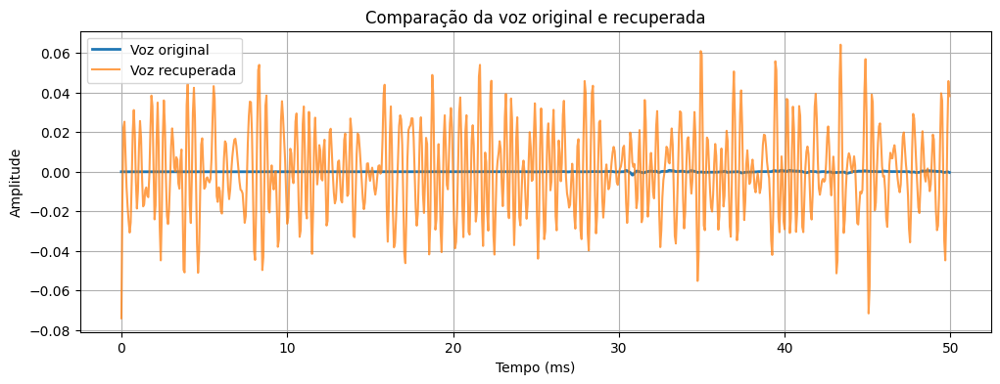

In [33]:

# ==========================================
# ETAPA 20 - TRANSMISSÃO FM DA SUA VOZ
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from IPython.display import Audio, display

# Parâmetros
fs = fs_audio
desvio = 3000
SNR_dB = 20

# 1. MODULAÇÃO FM
fase = 2 * np.pi * desvio * np.cumsum(voz) / fs
sinal_fm = np.exp(1j * fase)

# 2. CANAL COM RUÍDO AWGN
rng = np.random.default_rng(42)

potencia_sinal = np.mean(np.abs(sinal_fm)**2)
potencia_ruido = potencia_sinal / (10**(SNR_dB / 10))

ruido = np.sqrt(potencia_ruido / 2) * (
    rng.standard_normal(len(sinal_fm)) +
    1j * rng.standard_normal(len(sinal_fm))
)

sinal_recebido = sinal_fm + ruido

# 3. DEMODULAÇÃO FM
diferenca_fase = np.angle(
    sinal_recebido[1:] *
    np.conj(sinal_recebido[:-1])
)

audio_demodulado = (
    diferenca_fase * fs / (2 * np.pi * desvio)
)

# 4. FILTRO PASSA-BAIXAS
sos = butter(
    4,
    3000,
    fs=fs,
    btype="low",
    output="sos"
)

voz_recuperada = sosfiltfilt(
    sos, audio_demodulado
)

# 5. REPRODUZIR ÁUDIOS
print("ÁUDIO ORIGINAL:")
display(Audio(voz, rate=fs, normalize=True))

print(f"ÁUDIO RECUPERADO - SNR = {SNR_dB} dB:")
display(Audio(voz_recuperada, rate=fs, normalize=True))

# 6. COMPARAÇÃO VISUAL
# Mostrar apenas os primeiros 50 ms
n = min(int(0.05 * fs), len(voz_recuperada))
tempo = np.arange(n) / fs * 1000

plt.figure(figsize=(12, 4))

plt.plot(
    tempo, voz[1:n+1],
    label="Voz original",
    linewidth=2
)

plt.plot(
    tempo, voz_recuperada[:n],
    label="Voz recuperada",
    alpha=0.75
)

plt.xlabel("Tempo (ms)")
plt.ylabel("Amplitude")
plt.title("Comparação da voz original e recuperada")
plt.legend()
plt.grid(True)
plt.show()


In [34]:

# ==========================================
# ETAPA 21 - PAINEL INTERATIVO DO RECEPTOR SDR
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from scipy.signal import butter, sosfiltfilt, welch
from IPython.display import Audio, display, clear_output

fs = fs_audio
desvio = 3000

# Modulação FM da voz
fase = 2*np.pi*desvio*np.cumsum(voz)/fs
sinal_fm = np.exp(1j*fase)

# Controles
controle_snr = widgets.IntSlider(
    value=20,
    min=0,
    max=30,
    step=5,
    description="SNR (dB):",
    continuous_update=False
)

botao = widgets.Button(
    description="Executar receptor SDR",
    button_style="success"
)

saida = widgets.Output()

def executar_receptor(_):
    with saida:
        clear_output(wait=True)

        snr_db = controle_snr.value
        rng = np.random.default_rng(42)

        # Canal AWGN
        potencia_ruido = 1 / (10**(snr_db/10))

        ruido = np.sqrt(potencia_ruido/2) * (
            rng.standard_normal(len(sinal_fm)) +
            1j*rng.standard_normal(len(sinal_fm))
        )

        rx = sinal_fm + ruido

        # Demodulação FM
        diferenca_fase = np.angle(
            rx[1:] * np.conj(rx[:-1])
        )

        demod = diferenca_fase * fs / (2*np.pi*desvio)

        # Filtro passa-baixas
        sos = butter(
            4, 3000,
            fs=fs,
            btype="low",
            output="sos"
        )

        recuperado = sosfiltfilt(sos, demod)

        # Métrica de erro
        original = voz[1:]
        mse = np.mean((original - recuperado)**2)

        print(f"SNR de entrada: {snr_db} dB")
        print(f"Erro quadrático médio (MSE): {mse:.6f}")

        # Espectro do sinal IQ recebido
        frequencias, psd = welch(
            rx,
            fs=fs,
            nperseg=min(2048, len(rx)),
            return_onesided=False
        )

        ordem = np.argsort(frequencias)

        plt.figure(figsize=(11, 4))
        plt.plot(
            frequencias[ordem]/1000,
            10*np.log10(psd[ordem] + 1e-15)
        )
        plt.title("Espectro do sinal FM recebido")
        plt.xlabel("Frequência em banda-base (kHz)")
        plt.ylabel("PSD (dB/Hz)")
        plt.grid(True)
        plt.show()

        # Comparação temporal
        n = min(int(0.05*fs), len(recuperado))
        tempo = np.arange(n)/fs*1000

        plt.figure(figsize=(11, 4))
        plt.plot(
            tempo, original[:n],
            label="Original"
        )
        plt.plot(
            tempo, recuperado[:n],
            label="Recuperado",
            alpha=0.7
        )
        plt.title("Comparação do áudio")
        plt.xlabel("Tempo (ms)")
        plt.ylabel("Amplitude")
        plt.legend()
        plt.grid(True)
        plt.show()

        print("Áudio recuperado:")
        display(Audio(recuperado, rate=fs, normalize=True))

botao.on_click(executar_receptor)

display(
    widgets.VBox([
        widgets.HTML("<h3>Receptor SDR FM - Simulação</h3>"),
        controle_snr,
        botao,
        saida
    ])
)


In [35]:

# ==========================================
# ETAPA 22 - DIAGNÓSTICO DO RUÍDO
# ==========================================

import numpy as np
from scipy.signal import butter, sosfiltfilt
from IPython.display import Audio, display

fs = fs_audio
desvio = 3000

# MODULAÇÃO FM
fase = 2 * np.pi * desvio * np.cumsum(voz) / fs
tx = np.exp(1j * fase)

# FUNÇÃO DE DEMODULAÇÃO
def demodular_fm(rx):
    diferenca_fase = np.angle(
        rx[1:] * np.conj(rx[:-1])
    )

    audio = diferenca_fase * fs / (2*np.pi*desvio)

    sos = butter(
        4, 3000,
        fs=fs,
        btype="low",
        output="sos"
    )

    return sosfiltfilt(sos, audio)

# TESTE 1 - ORIGINAL
print("1. ÁUDIO ORIGINAL")
display(Audio(voz, rate=fs, normalize=True))

# TESTE 2 - FM SEM RUÍDO
recuperado_ideal = demodular_fm(tx)

print("2. FM SEM RUÍDO")
display(Audio(recuperado_ideal, rate=fs, normalize=True))

# TESTE 3 - FM COM RUÍDO
snr_db = 20

rng = np.random.default_rng(42)
potencia_ruido = 10**(-snr_db/10)

ruido = np.sqrt(potencia_ruido/2) * (
    rng.standard_normal(len(tx)) +
    1j*rng.standard_normal(len(tx))
)

rx = tx + ruido

recuperado_ruidoso = demodular_fm(rx)

print("3. FM COM SNR = 20 dB")
display(Audio(recuperado_ruidoso, rate=fs, normalize=True))


1. ÁUDIO ORIGINAL


2. FM SEM RUÍDO


3. FM COM SNR = 20 dB



Áudio recuperado - Filtro 3000 Hz



Áudio recuperado - Filtro 2000 Hz



Áudio recuperado - Filtro 1500 Hz


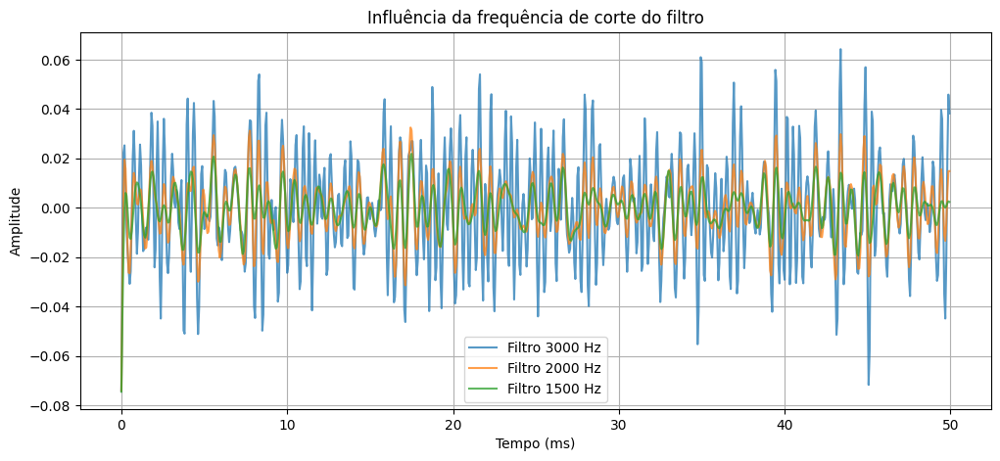

In [36]:

# ==========================================
# ETAPA 23 - COMPARAÇÃO DE FILTROS
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt
from IPython.display import Audio, display

fs = fs_audio
desvio = 3000
snr_db = 20

# 1. Modular a voz
fase = 2*np.pi*desvio*np.cumsum(voz)/fs
tx = np.exp(1j*fase)

# 2. Adicionar ruído AWGN
rng = np.random.default_rng(42)

potencia_ruido = 10**(-snr_db/10)

ruido = np.sqrt(potencia_ruido/2) * (
    rng.standard_normal(len(tx)) +
    1j*rng.standard_normal(len(tx))
)

rx = tx + ruido

# 3. Demodular o sinal
diferenca_fase = np.angle(
    rx[1:] * np.conj(rx[:-1])
)

demodulado = diferenca_fase * fs/(2*np.pi*desvio)

# 4. Comparar filtros
frequencias_corte = [3000, 2000, 1500]

plt.figure(figsize=(12, 5))

n = min(int(0.05*fs), len(demodulado))
tempo = np.arange(n)/fs*1000

for fc in frequencias_corte:

    sos = butter(
        4, fc,
        fs=fs,
        btype="low",
        output="sos"
    )

    recuperado = sosfiltfilt(sos, demodulado)

    print(f"\nÁudio recuperado - Filtro {fc} Hz")
    display(Audio(recuperado, rate=fs, normalize=True))

    plt.plot(
        tempo,
        recuperado[:n],
        label=f"Filtro {fc} Hz",
        alpha=0.75
    )

plt.title("Influência da frequência de corte do filtro")
plt.xlabel("Tempo (ms)")
plt.ylabel("Amplitude")
plt.legend()
plt.grid(True)
plt.show()


Filtro: 3000 Hz
  MSE: 0.000573
  SNR de saída: 10.35 dB
-----------------------------------
Filtro: 2000 Hz
  MSE: 0.000253
  SNR de saída: 13.90 dB
-----------------------------------
Filtro: 1500 Hz
  MSE: 0.000175
  SNR de saída: 15.50 dB
-----------------------------------


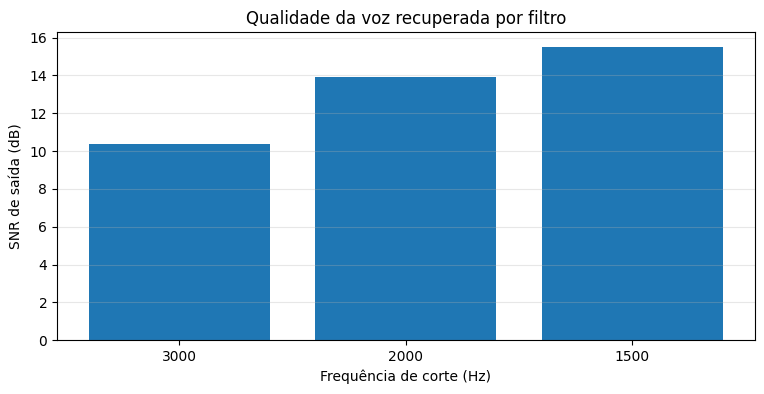

In [37]:

# ==========================================
# ETAPA 24 - AVALIAÇÃO QUANTITATIVA DOS FILTROS
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

# Sinal original alinhado com a demodulação
original = voz[1:]

frequencias_corte = [3000, 2000, 1500]

resultados = []

for fc in frequencias_corte:

    # Aplicar filtro
    sos = butter(
        4, fc,
        fs=fs,
        btype="low",
        output="sos"
    )

    recuperado = sosfiltfilt(sos, demodulado)

    # Ignorar as bordas para reduzir efeitos transitórios
    margem = min(100, len(original)//10)

    ref = original[margem:len(original)-margem]
    estimado = recuperado[margem:len(recuperado)-margem]

    # Erro quadrático médio
    mse = np.mean((ref - estimado)**2)

    # SNR de saída
    potencia_sinal = np.mean(ref**2)
    potencia_erro = np.mean((ref - estimado)**2)

    snr_saida = 10*np.log10(
        potencia_sinal / (potencia_erro + 1e-15)
    )

    resultados.append((fc, mse, snr_saida))

    print(f"Filtro: {fc} Hz")
    print(f"  MSE: {mse:.6f}")
    print(f"  SNR de saída: {snr_saida:.2f} dB")
    print("-"*35)

# Gráfico comparativo
plt.figure(figsize=(9, 4))

plt.bar(
    [str(r[0]) for r in resultados],
    [r[2] for r in resultados]
)

plt.xlabel("Frequência de corte (Hz)")
plt.ylabel("SNR de saída (dB)")
plt.title("Qualidade da voz recuperada por filtro")
plt.grid(axis="y", alpha=0.3)
plt.show()


Frequência de corte ótima: 1100 Hz
SNR máxima de saída: 16.24 dB


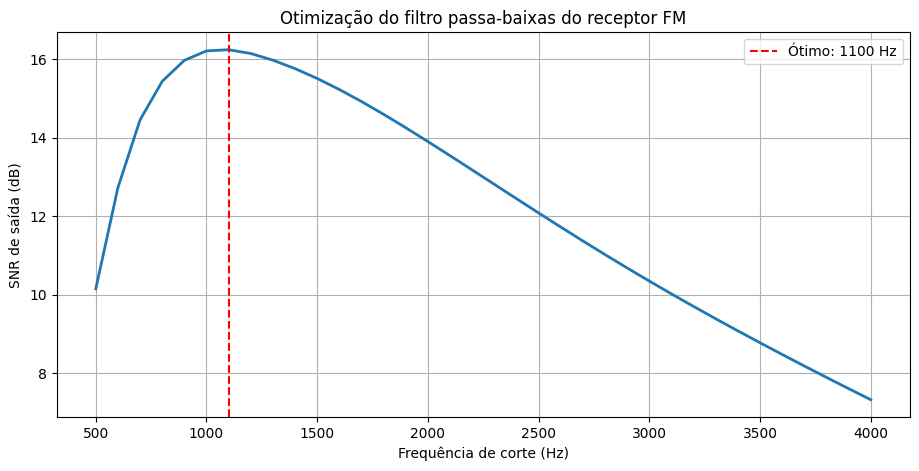

In [38]:

# ==========================================
# ETAPA 25 - OTIMIZAÇÃO DO FILTRO DO RECEPTOR
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

# Frequências de corte a testar
frequencias = np.arange(500, 4001, 100)

snrs_saida = []
mses = []

original = voz[1:]

margem = 100

ref = original[margem:-margem]

for fc in frequencias:

    # Criar filtro Butterworth
    sos = butter(
        4,
        fc,
        fs=fs,
        btype="low",
        output="sos"
    )

    # Filtrar sinal demodulado
    recuperado = sosfiltfilt(sos, demodulado)

    estimado = recuperado[margem:-margem]

    # Calcular MSE
    mse = np.mean((ref - estimado)**2)

    # Calcular SNR de saída
    potencia_sinal = np.mean(ref**2)

    snr = 10*np.log10(
        potencia_sinal/(mse + 1e-15)
    )

    mses.append(mse)
    snrs_saida.append(snr)

# Encontrar melhor frequência
indice = np.argmax(snrs_saida)

fc_otima = frequencias[indice]
snr_maxima = snrs_saida[indice]

print(f"Frequência de corte ótima: {fc_otima} Hz")
print(f"SNR máxima de saída: {snr_maxima:.2f} dB")

# Gráfico
plt.figure(figsize=(11, 5))

plt.plot(
    frequencias,
    snrs_saida,
    linewidth=2
)

plt.axvline(
    fc_otima,
    color="red",
    linestyle="--",
    label=f"Ótimo: {fc_otima} Hz"
)

plt.xlabel("Frequência de corte (Hz)")
plt.ylabel("SNR de saída (dB)")
plt.title("Otimização do filtro passa-baixas do receptor FM")
plt.legend()
plt.grid(True)
plt.show()


In [39]:

# ==========================================
# ETAPA 26 - RECEPTOR FM COM FILTRO OTIMIZADO
# ==========================================

from scipy.signal import butter, sosfiltfilt
from IPython.display import Audio, display

# Frequência ótima encontrada na etapa anterior
fc = int(fc_otima)

# Criar filtro otimizado
sos_otimo = butter(
    4,
    fc,
    fs=fs,
    btype="low",
    output="sos"
)

# Filtrar áudio demodulado
voz_otimizada = sosfiltfilt(
    sos_otimo,
    demodulado
)

print("1. ÁUDIO ORIGINAL")
display(Audio(voz, rate=fs, normalize=True))

print("2. ÁUDIO RECUPERADO - FILTRO 3000 Hz")
sos_3000 = butter(
    4, 3000,
    fs=fs,
    btype="low",
    output="sos"
)
voz_3000 = sosfiltfilt(sos_3000, demodulado)
display(Audio(voz_3000, rate=fs, normalize=True))

print(f"3. ÁUDIO RECUPERADO - FILTRO OTIMIZADO {fc} Hz")
display(Audio(voz_otimizada, rate=fs, normalize=True))


1. ÁUDIO ORIGINAL


2. ÁUDIO RECUPERADO - FILTRO 3000 Hz


3. ÁUDIO RECUPERADO - FILTRO OTIMIZADO 1100 Hz


In [40]:

# ==========================================
# ETAPA 27 - PAINEL INTERATIVO SDR FM
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
import ipywidgets as widgets

from scipy.signal import butter, sosfiltfilt, spectrogram, welch
from IPython.display import Audio, display, clear_output

fs = fs_audio
desvio = 3000

# Modulação FM da voz
fase = 2*np.pi*desvio*np.cumsum(voz)/fs
tx = np.exp(1j*fase)

# Controles do receptor
snr_slider = widgets.IntSlider(
    value=20, min=0, max=30, step=5,
    description="SNR (dB):",
    continuous_update=False
)

filtro_slider = widgets.IntSlider(
    value=1100, min=500, max=4000, step=100,
    description="Filtro (Hz):",
    continuous_update=False
)

botao = widgets.Button(
    description="Executar receptor",
    button_style="success"
)

saida = widgets.Output()

def executar_receptor(_):
    with saida:
        clear_output(wait=True)

        snr_db = snr_slider.value
        fc = filtro_slider.value

        # Canal AWGN
        rng = np.random.default_rng(42)
        potencia_ruido = 10**(-snr_db/10)

        ruido = np.sqrt(potencia_ruido/2) * (
            rng.standard_normal(len(tx)) +
            1j*rng.standard_normal(len(tx))
        )

        rx = tx + ruido

        # Demodulação FM
        diferenca_fase = np.angle(
            rx[1:] * np.conj(rx[:-1])
        )

        demodulado = diferenca_fase*fs/(2*np.pi*desvio)

        # Filtro passa-baixas
        sos = butter(
            4, fc, fs=fs,
            btype="low",
            output="sos"
        )

        recuperado = sosfiltfilt(sos, demodulado)

        # Métricas
        original = voz[1:]
        margem = min(100, len(original)//10)

        ref = original[margem:-margem]
        est = recuperado[margem:-margem]

        mse = np.mean((ref-est)**2)
        snr_saida = 10*np.log10(
            np.mean(ref**2)/(mse+1e-15)
        )

        print(f"SNR de entrada: {snr_db} dB")
        print(f"Frequência de corte: {fc} Hz")
        print(f"MSE: {mse:.6f}")
        print(f"SNR de saída: {snr_saida:.2f} dB")

        # Espectro
        f, psd = welch(
            rx, fs=fs,
            nperseg=min(2048, len(rx)),
            return_onesided=False
        )

        ordem = np.argsort(f)

        plt.figure(figsize=(11, 3))
        plt.plot(
            f[ordem]/1000,
            10*np.log10(psd[ordem]+1e-15)
        )
        plt.title("Espectro do sinal IQ recebido")
        plt.xlabel("Frequência (kHz)")
        plt.ylabel("PSD (dB/Hz)")
        plt.grid(True)
        plt.show()

        # Waterfall
        f2, t2, S = spectrogram(
            rx, fs=fs,
            nperseg=512,
            noverlap=448,
            return_onesided=False,
            mode="psd"
        )

        ordem2 = np.argsort(f2)

        plt.figure(figsize=(11, 4))
        plt.pcolormesh(
            t2,
            f2[ordem2]/1000,
            10*np.log10(S[ordem2, :]+1e-15),
            shading="auto",
            cmap="viridis"
        )
        plt.title("Waterfall do sinal FM recebido")
        plt.xlabel("Tempo (s)")
        plt.ylabel("Frequência (kHz)")
        plt.colorbar(label="PSD (dB/Hz)")
        plt.show()

        # Comparação temporal
        n = min(int(0.05*fs), len(recuperado))
        tempo = np.arange(n)/fs*1000

        plt.figure(figsize=(11, 3))
        plt.plot(
            tempo, original[:n],
            label="Original"
        )
        plt.plot(
            tempo, recuperado[:n],
            label="Recuperado",
            alpha=0.7
        )
        plt.title("Comparação temporal da voz")
        plt.xlabel("Tempo (ms)")
        plt.ylabel("Amplitude")
        plt.legend()
        plt.grid(True)
        plt.show()

        print("Áudio recuperado:")
        display(Audio(
            recuperado,
            rate=fs,
            normalize=True
        ))

botao.on_click(executar_receptor)

display(widgets.VBox([
    widgets.HTML(
        "<h3>SDR FM Receiver — Interactive Laboratory</h3>"
    ),
    snr_slider,
    filtro_slider,
    botao,
    saida
]))


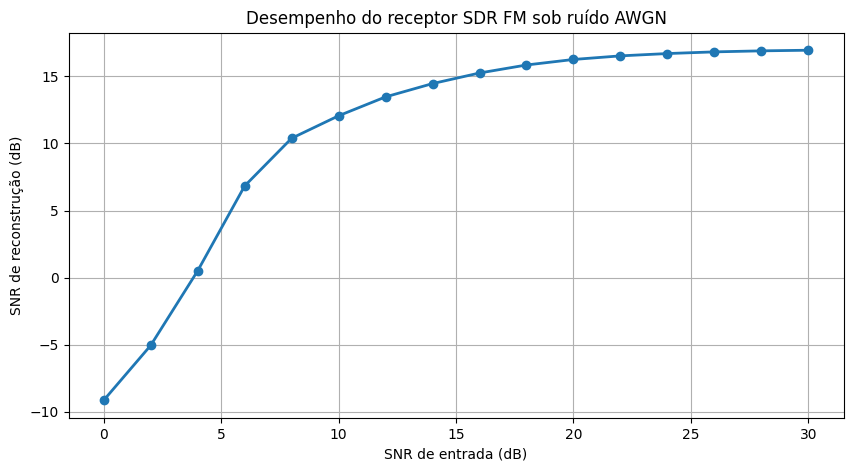

Resultados:
SNR entrada:  0 dB | SNR reconstrução: -9.14 dB
SNR entrada:  2 dB | SNR reconstrução: -5.05 dB
SNR entrada:  4 dB | SNR reconstrução: 0.51 dB
SNR entrada:  6 dB | SNR reconstrução: 6.83 dB
SNR entrada:  8 dB | SNR reconstrução: 10.38 dB
SNR entrada: 10 dB | SNR reconstrução: 12.06 dB
SNR entrada: 12 dB | SNR reconstrução: 13.47 dB
SNR entrada: 14 dB | SNR reconstrução: 14.46 dB
SNR entrada: 16 dB | SNR reconstrução: 15.25 dB
SNR entrada: 18 dB | SNR reconstrução: 15.85 dB
SNR entrada: 20 dB | SNR reconstrução: 16.26 dB
SNR entrada: 22 dB | SNR reconstrução: 16.53 dB
SNR entrada: 24 dB | SNR reconstrução: 16.70 dB
SNR entrada: 26 dB | SNR reconstrução: 16.82 dB
SNR entrada: 28 dB | SNR reconstrução: 16.90 dB
SNR entrada: 30 dB | SNR reconstrução: 16.95 dB


In [41]:

# ==========================================
# ETAPA 28 - DESEMPENHO DO RECEPTOR SDR FM
# ==========================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

# Parâmetros
fs = fs_audio
desvio = 3000
fc = 1100

snrs_entrada = np.arange(0, 31, 2)
snrs_saida = []

# Modulação FM
fase = 2*np.pi*desvio*np.cumsum(voz)/fs
tx = np.exp(1j*fase)

# Filtro
sos = butter(4, fc, fs=fs, btype="low", output="sos")

# Gerador de números aleatórios
rng = np.random.default_rng(42)

for snr_db in snrs_entrada:

    # Canal AWGN
    potencia_ruido = 10**(-snr_db/10)

    ruido = np.sqrt(potencia_ruido/2) * (
        rng.standard_normal(len(tx)) +
        1j*rng.standard_normal(len(tx))
    )

    rx = tx + ruido

    # Demodulação FM
    diferenca_fase = np.angle(
        rx[1:] * np.conj(rx[:-1])
    )

    demodulado = diferenca_fase*fs/(2*np.pi*desvio)

    # Filtragem
    recuperado = sosfiltfilt(sos, demodulado)

    # Comparação com sinal original
    margem = 100

    original = voz[1:][margem:-margem]
    estimado = recuperado[margem:-margem]

    erro = np.mean((original-estimado)**2)

    snr_saida = 10*np.log10(
        np.mean(original**2)/(erro+1e-15)
    )

    snrs_saida.append(snr_saida)

# Gráfico
plt.figure(figsize=(10, 5))

plt.plot(
    snrs_entrada,
    snrs_saida,
    marker="o",
    linewidth=2
)

plt.xlabel("SNR de entrada (dB)")
plt.ylabel("SNR de reconstrução (dB)")
plt.title("Desempenho do receptor SDR FM sob ruído AWGN")
plt.grid(True)
plt.show()

print("Resultados:")
for entrada, saida in zip(snrs_entrada, snrs_saida):
    print(f"SNR entrada: {entrada:2d} dB | SNR reconstrução: {saida:.2f} dB")


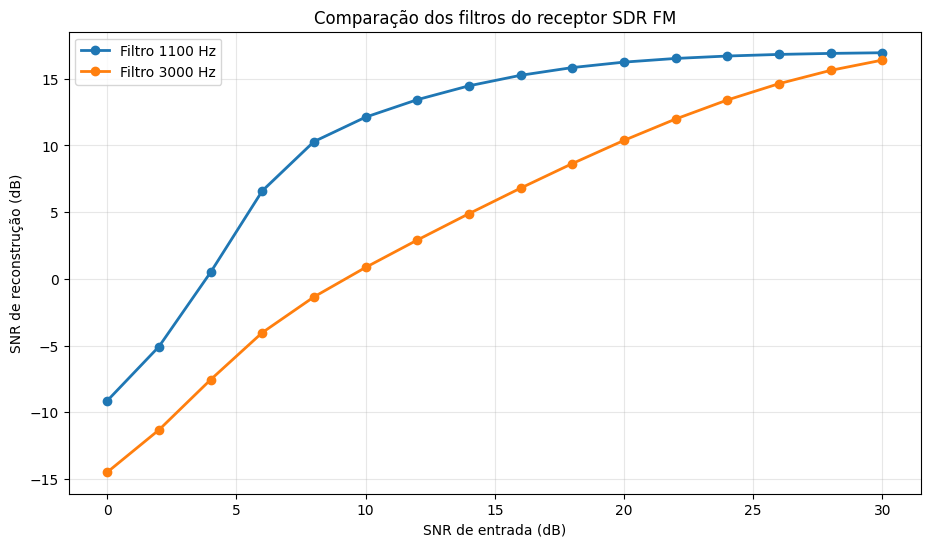


COMPARAÇÃO DOS FILTROS
-------------------------------------------------------
Entrada:  0 dB | 1100 Hz:  -9.13 dB | 3000 Hz: -14.48 dB | Diferença: +5.36 dB
Entrada:  2 dB | 1100 Hz:  -5.07 dB | 3000 Hz: -11.32 dB | Diferença: +6.24 dB
Entrada:  4 dB | 1100 Hz:   0.50 dB | 3000 Hz:  -7.55 dB | Diferença: +8.05 dB
Entrada:  6 dB | 1100 Hz:   6.60 dB | 3000 Hz:  -4.02 dB | Diferença: +10.62 dB
Entrada:  8 dB | 1100 Hz:  10.29 dB | 3000 Hz:  -1.35 dB | Diferença: +11.64 dB
Entrada: 10 dB | 1100 Hz:  12.12 dB | 3000 Hz:   0.86 dB | Diferença: +11.26 dB
Entrada: 12 dB | 1100 Hz:  13.43 dB | 3000 Hz:   2.91 dB | Diferença: +10.52 dB
Entrada: 14 dB | 1100 Hz:  14.47 dB | 3000 Hz:   4.89 dB | Diferença: +9.58 dB
Entrada: 16 dB | 1100 Hz:  15.26 dB | 3000 Hz:   6.80 dB | Diferença: +8.46 dB
Entrada: 18 dB | 1100 Hz:  15.84 dB | 3000 Hz:   8.64 dB | Diferença: +7.20 dB
Entrada: 20 dB | 1100 Hz:  16.24 dB | 3000 Hz:  10.38 dB | Diferença: +5.87 dB
Entrada: 22 dB | 1100 Hz:  16.52 dB | 3000 Hz: 

In [42]:

# ================================================
# ETAPA 29 - COMPARAÇÃO EXPERIMENTAL DOS FILTROS
# Receptor SDR FM - Canal AWGN
# ================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import butter, sosfiltfilt

# Parâmetros
fs = fs_audio
desvio = 3000
frequencias_corte = [1100, 3000]
snrs_entrada = np.arange(0, 31, 2)
num_realizacoes = 20

# Modulação FM
fase = 2 * np.pi * desvio * np.cumsum(voz) / fs
tx = np.exp(1j * fase)

# Filtros
filtros = {
    fc: butter(4, fc, fs=fs, btype="low", output="sos")
    for fc in frequencias_corte
}

# Referência para cálculo do erro
margem = 100
referencia = voz[1:][margem:-margem]
potencia_ref = np.mean(referencia**2)

# Armazenar resultados
resultados = {
    fc: {"media": [], "desvio": []}
    for fc in frequencias_corte
}

rng = np.random.default_rng(42)

for snr_db in snrs_entrada:

    # Armazenar erros de cada realização
    erros = {fc: [] for fc in frequencias_corte}

    for repeticao in range(num_realizacoes):

        # Canal AWGN
        potencia_ruido = 10**(-snr_db / 10)

        ruido = np.sqrt(potencia_ruido / 2) * (
            rng.standard_normal(len(tx)) +
            1j * rng.standard_normal(len(tx))
        )

        rx = tx + ruido

        # Demodulação FM
        diferenca_fase = np.angle(
            rx[1:] * np.conj(rx[:-1])
        )

        demodulado = (
            diferenca_fase * fs / (2 * np.pi * desvio)
        )

        # Aplicar ambos os filtros ao mesmo sinal
        for fc in frequencias_corte:

            recuperado = sosfiltfilt(
                filtros[fc], demodulado
            )

            estimado = recuperado[margem:-margem]

            mse = np.mean(
                (referencia - estimado)**2
            )

            erros[fc].append(mse)

    # Calcular SNR a partir do MSE médio
    # e dispersão das SNRs individuais
    for fc in frequencias_corte:

        erros_fc = np.array(erros[fc])

        snr_media = 10 * np.log10(
            potencia_ref / (np.mean(erros_fc) + 1e-15)
        )

        snrs_individuais = 10 * np.log10(
            potencia_ref / (erros_fc + 1e-15)
        )

        resultados[fc]["media"].append(snr_media)
        resultados[fc]["desvio"].append(
            np.std(snrs_individuais)
        )

# ================================================
# GRÁFICO COMPARATIVO
# ================================================

plt.figure(figsize=(11, 6))

for fc in frequencias_corte:

    media = np.array(resultados[fc]["media"])
    desvio_padrao = np.array(resultados[fc]["desvio"])

    plt.plot(
        snrs_entrada,
        media,
        marker="o",
        linewidth=2,
        label=f"Filtro {fc} Hz"
    )

    plt.fill_between(
        snrs_entrada,
        media - desvio_padrao,
        media + desvio_padrao,
        alpha=0.15
    )

plt.xlabel("SNR de entrada (dB)")
plt.ylabel("SNR de reconstrução (dB)")
plt.title("Comparação dos filtros do receptor SDR FM")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# ================================================
# RESULTADOS NUMÉRICOS
# ================================================

print("\nCOMPARAÇÃO DOS FILTROS")
print("-" * 55)

for i, snr_db in enumerate(snrs_entrada):

    snr_1100 = resultados[1100]["media"][i]
    snr_3000 = resultados[3000]["media"][i]

    melhoria = snr_1100 - snr_3000

    print(
        f"Entrada: {snr_db:2d} dB | "
        f"1100 Hz: {snr_1100:6.2f} dB | "
        f"3000 Hz: {snr_3000:6.2f} dB | "
        f"Diferença: {melhoria:+.2f} dB"
    )


Selecione a segunda gravação:


Saving WhatsApp Ptt 2026-10-30 at 17.54.07.ogg to WhatsApp Ptt 2026-10-30 at 17.54.07.ogg

===== VALIDAÇÃO COM NOVA VOZ =====
Filtro 1100 Hz | MSE: 0.000399 | SNR: 12.82 dB
Filtro 3000 Hz | MSE: 0.000803 | SNR: 9.78 dB

ÁUDIO ORIGINAL



ÁUDIO RECUPERADO - FILTRO 1100 Hz



ÁUDIO RECUPERADO - FILTRO 3000 Hz


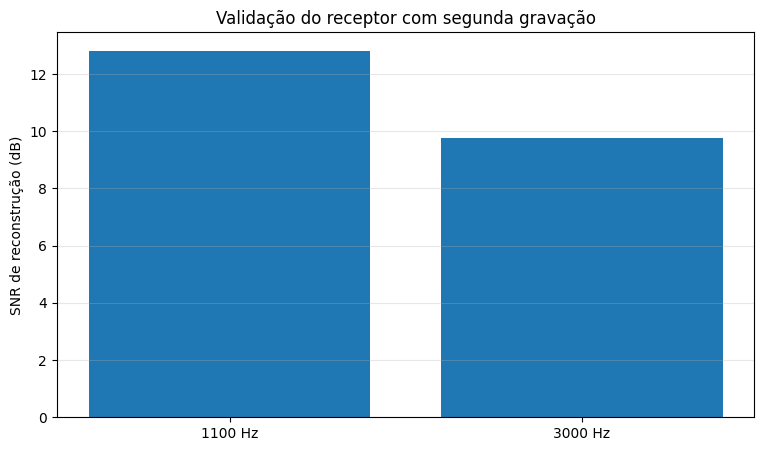

In [43]:

# ==============================================
# ETAPA 30 - VALIDAÇÃO COM SEGUNDA GRAVAÇÃO
# ==============================================

import numpy as np
import matplotlib.pyplot as plt
import soundfile as sf
import subprocess

from google.colab import files
from scipy.signal import butter, sosfiltfilt
from IPython.display import Audio, display

# 1. CARREGAR NOVO ÁUDIO
print("Selecione a segunda gravação:")
uploaded = files.upload()
arquivo = next(iter(uploaded))

# Converter para WAV mono, 16 kHz
subprocess.run([
    "ffmpeg", "-y", "-loglevel", "error",
    "-i", arquivo,
    "-ar", "16000",
    "-ac", "1",
    "segunda_gravacao.wav"
], check=True)

voz_teste, fs_teste = sf.read("segunda_gravacao.wav")

# Normalizar
voz_teste = voz_teste.astype(float)
pico = np.max(np.abs(voz_teste))

if pico > 0:
    voz_teste = 0.7 * voz_teste / pico

# 2. PARÂMETROS FIXOS
fs = fs_teste
desvio = 3000
fc_otima = 1100
snr_db = 20

# 3. MODULAÇÃO FM
fase = 2*np.pi*desvio*np.cumsum(voz_teste)/fs
tx_teste = np.exp(1j*fase)

# 4. CANAL AWGN
rng = np.random.default_rng(123)

potencia_ruido = 10**(-snr_db/10)

ruido = np.sqrt(potencia_ruido/2) * (
    rng.standard_normal(len(tx_teste)) +
    1j*rng.standard_normal(len(tx_teste))
)

rx_teste = tx_teste + ruido

# 5. DEMODULAÇÃO FM
fase_diff = np.angle(
    rx_teste[1:] * np.conj(rx_teste[:-1])
)

demodulado_teste = fase_diff*fs/(2*np.pi*desvio)

# 6. COMPARAR FILTROS
frequencias = [1100, 3000]
resultados_teste = {}

referencia = voz_teste[1:]
margem = 100

for fc in frequencias:

    sos = butter(
        4, fc,
        fs=fs,
        btype="low",
        output="sos"
    )

    recuperado = sosfiltfilt(
        sos, demodulado_teste
    )

    ref = referencia[margem:-margem]
    est = recuperado[margem:-margem]

    mse = np.mean((ref-est)**2)

    snr_saida = 10*np.log10(
        np.mean(ref**2)/(mse+1e-15)
    )

    resultados_teste[fc] = {
        "audio": recuperado,
        "mse": mse,
        "snr": snr_saida
    }

# 7. RESULTADOS
print("\n===== VALIDAÇÃO COM NOVA VOZ =====")

for fc in frequencias:
    print(
        f"Filtro {fc} Hz | "
        f"MSE: {resultados_teste[fc]['mse']:.6f} | "
        f"SNR: {resultados_teste[fc]['snr']:.2f} dB"
    )

print("\nÁUDIO ORIGINAL")
display(Audio(voz_teste, rate=fs))

for fc in frequencias:
    print(f"\nÁUDIO RECUPERADO - FILTRO {fc} Hz")
    display(Audio(
        resultados_teste[fc]["audio"],
        rate=fs,
        normalize=True
    ))

# 8. GRÁFICO COMPARATIVO
plt.figure(figsize=(9, 5))

plt.bar(
    ["1100 Hz", "3000 Hz"],
    [
        resultados_teste[1100]["snr"],
        resultados_teste[3000]["snr"]
    ]
)

plt.ylabel("SNR de reconstrução (dB)")
plt.title("Validação do receptor com segunda gravação")
plt.grid(axis="y", alpha=0.3)
plt.show()
